In [1]:
import os
import numpy as np
import sympy as sp
import torch

from SymbolicMathematics.src.envs import set_cover_utils
from src.utils import AttrDict
from src.envs import build_env
from src.model import build_modules

from src.utils import to_cuda
from src.envs.sympy_utils import simplify
from src.envs.set_cover_utils import validate_set_cover_solution

import json
import matplotlib.pyplot as plt

Reporting
Plotting validation and test - Accuracy and loss

In [3]:
print("Current Working Directory:", os.getcwd())

Current Working Directory: /Users/sanda/Documents/University/Term5/Thesis/Codes/SetCoverTransformer/SymbolicMathematics


In [8]:
# Load the metrics from the JSON file
file_path_model1_metrics = 'Model1/metrics1.json'
file_path_model2_metrics = 'Model2/metrics2.json'

In [18]:
with open(file_path_model1_metrics, 'r') as f:
    metrics1 = json.load(f)

In [19]:
with open(file_path_model2_metrics, 'r') as f:
    metrics2 = json.load(f)

In [24]:
# Extract validation and test metrics
#For Model1:
validation_loss_epochs_model1 = metrics1['validation_loss_epochs']
validation_accuracy_epochs_model1 = metrics1['validation_accuracy_epochs']
test_loss_epochs_model1 = metrics1['test_loss_epochs']
test_accuracy_epochs_model1 = metrics1['test_accuracy_epochs']
#For Model2:
validation_loss_epochs_model2 = metrics2['validation_loss_epochs']
validation_accuracy_epochs_model2 = metrics2['validation_accuracy_epochs']
test_loss_epochs_model2 = metrics2['test_loss_epochs']
test_accuracy_epochs_model2 = metrics2['test_accuracy_epochs']

# Find minimum values for Model 1
min_val_loss1 = min(validation_loss_epochs_model1)
min_val_loss_epoch1 = validation_loss_epochs_model1.index(min_val_loss1) + 1
max_val_acc1 = max(validation_accuracy_epochs_model1)
max_val_acc_epoch1 = validation_accuracy_epochs_model1.index(max_val_acc1) + 1
min_test_loss1 = min(test_loss_epochs_model1)
min_test_loss_epoch1 = test_loss_epochs_model1.index(min_test_loss1) + 1
max_test_acc1 = max(test_accuracy_epochs_model1)
max_test_acc_epoch1 = test_accuracy_epochs_model1.index(max_test_acc1) + 1

# Find minimum values for Model 2
min_val_loss2 = min(validation_loss_epochs_model2)
min_val_loss_epoch2 = validation_loss_epochs_model2.index(min_val_loss2) + 1
max_val_acc2 = max(validation_accuracy_epochs_model2)
max_val_acc_epoch2 = validation_accuracy_epochs_model2.index(max_val_acc2) + 1
min_test_loss2 = min(test_loss_epochs_model2)
min_test_loss_epoch2 = test_loss_epochs_model2.index(min_test_loss2) + 1
max_test_acc2 = max(test_accuracy_epochs_model2)
max_test_acc_epoch2 = test_accuracy_epochs_model2.index(max_test_acc2) + 1

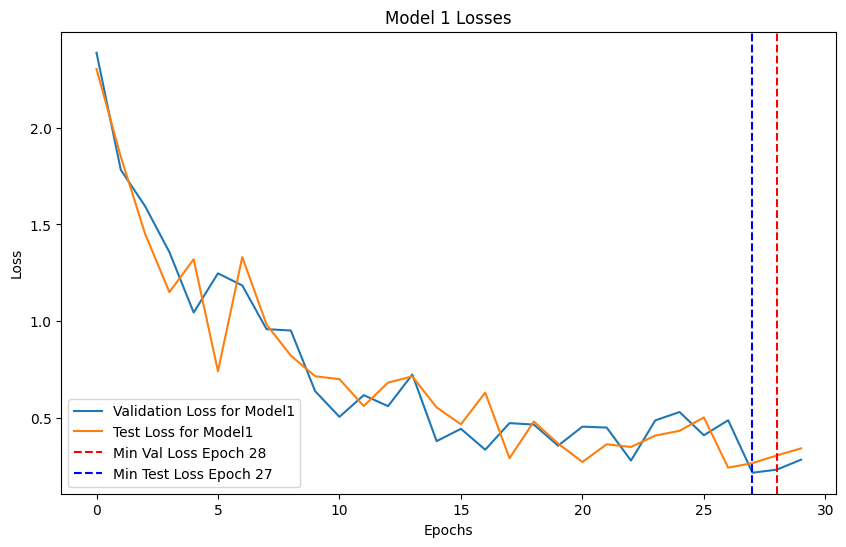

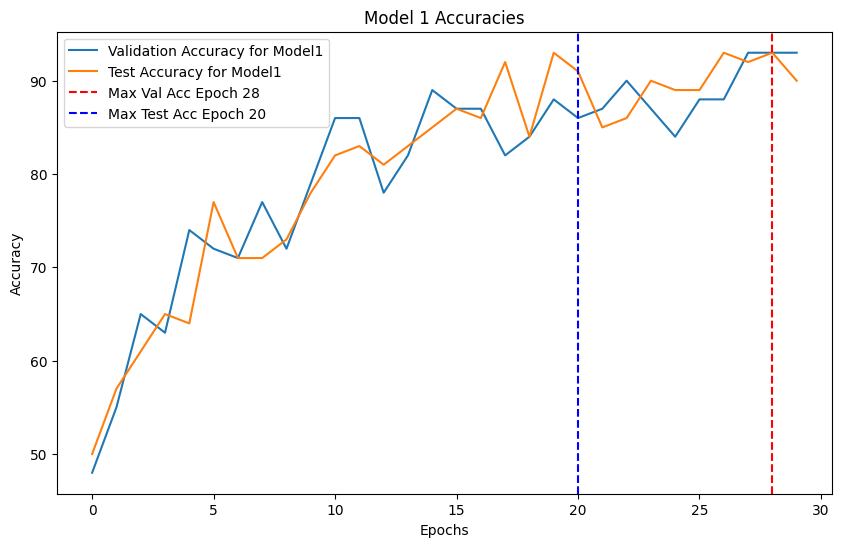

In [25]:
plt.figure(figsize=(10, 6))
plt.plot(validation_loss_epochs_model1, label='Validation Loss for Model1')
plt.plot(test_loss_epochs_model1, label='Test Loss for Model1')
plt.axvline(min_val_loss_epoch1, linestyle='--', color='r', label=f'Min Val Loss Epoch {min_val_loss_epoch1}')
plt.axvline(min_test_loss_epoch1, linestyle='--', color='b', label=f'Min Test Loss Epoch {min_test_loss_epoch1}')
plt.title('Model 1 Losses')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(validation_accuracy_epochs_model1, label='Validation Accuracy for Model1')
plt.plot(test_accuracy_epochs_model1, label='Test Accuracy for Model1')
plt.axvline(max_val_acc_epoch1, linestyle='--', color='r', label=f'Max Val Acc Epoch {max_val_acc_epoch1}')
plt.axvline(max_test_acc_epoch1, linestyle='--', color='b', label=f'Max Test Acc Epoch {max_test_acc_epoch1}')
plt.title('Model 1 Accuracies')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

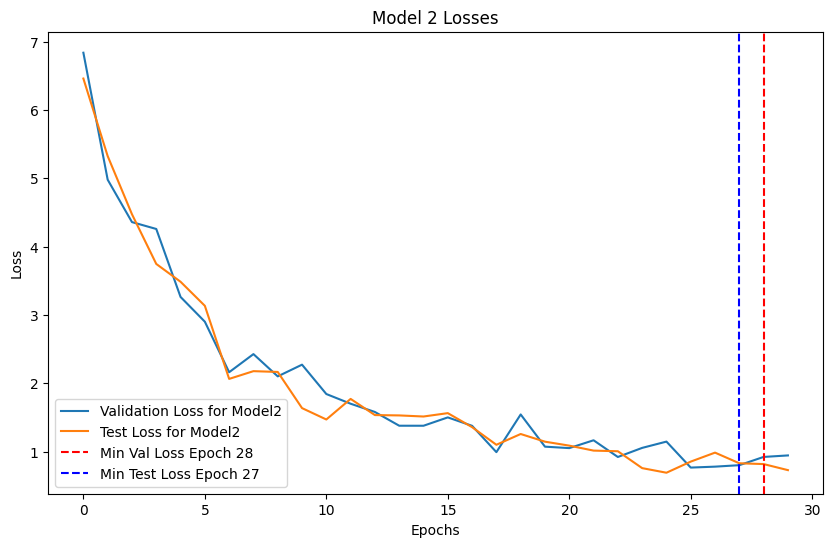

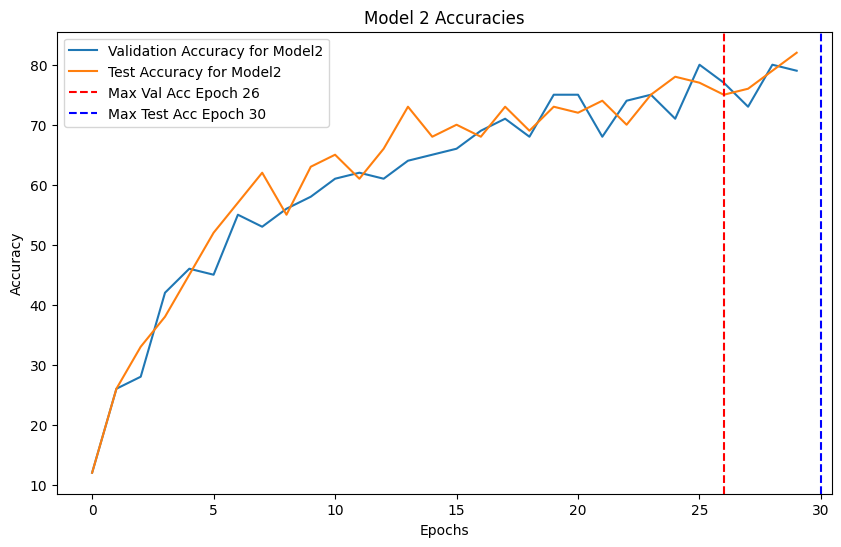

In [26]:
plt.figure(figsize=(10, 6))
plt.plot(validation_loss_epochs_model2, label='Validation Loss for Model2')
plt.plot(test_loss_epochs_model2, label='Test Loss for Model2')
plt.axvline(min_val_loss_epoch1, linestyle='--', color='r', label=f'Min Val Loss Epoch {min_val_loss_epoch1}')
plt.axvline(min_test_loss_epoch1, linestyle='--', color='b', label=f'Min Test Loss Epoch {min_test_loss_epoch1}')
plt.title('Model 2 Losses')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(validation_accuracy_epochs_model2, label='Validation Accuracy for Model2')
plt.plot(test_accuracy_epochs_model2, label='Test Accuracy for Model2')
plt.axvline(max_val_acc_epoch2, linestyle='--', color='r', label=f'Max Val Acc Epoch {max_val_acc_epoch2}')
plt.axvline(max_test_acc_epoch2, linestyle='--', color='b', label=f'Max Test Acc Epoch {max_test_acc_epoch2}')
plt.title('Model 2 Accuracies')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

Plot - valid answers according to my function for test and validation data

In [34]:
file_path_model1_results_training_validcheck = 'Model1/results_training1.json'
file_path_model1_results_validtest_validcheck = 'Model1/results_validtest1.json'
file_path_model2_results_training_validcheck = 'Model2/results_training2.json'
file_path_model2_results_validtest_validcheck = 'Model2/results_validtest2.json'

In [35]:
with open(file_path_model1_results_training_validcheck, 'r') as f:
    training1 = json.load(f)

In [36]:
with open(file_path_model1_results_validtest_validcheck, 'r') as f:
    validtest1 = json.load(f)

In [37]:
with open(file_path_model2_results_training_validcheck, 'r') as f:
    training2 = json.load(f)

In [38]:
with open(file_path_model2_results_validtest_validcheck, 'r') as f:
    validtest2 = json.load(f)

In [61]:
training_total_sets_model1= training1['training_totalsets_epochs']
training_valid_answers_model1= training1['training_valid_answers_epochs']
training_error_wrong_format_model1= training1['training_error_wrong_format_count_epochs']
training_error_no_subset_model1= training1['training_error_no_subset_count_epochs']
training_error_not_covering_model1 = training1['training_error_not_covering_count_epochs']
#training_not_optimal_model1= training1['training_error_not_optimal_count_epochs']

training_total_sets_model2= training2['training_totalsets_epochs']
training_valid_answers_model2= training2['training_valid_answers_epochs']
training_error_wrong_format_model2= training2['training_error_wrong_format_count_epochs']
training_error_no_subset_model2= training2['training_error_no_subset_count_epochs']
training_error_not_covering_model2 = training2['training_error_not_covering_count_epochs']
#training_not_optimal_model2= training2['training_error_not_optimal_count_epochs']

In [62]:
# Convert lists to numpy arrays for element-wise operations
training_total_sets_model1 = np.array(training1['training_totalsets_epochs'])
training_valid_answers_model1 = np.array(training1['training_valid_answers_epochs'])
training_error_wrong_format_model1 = np.array(training1['training_error_wrong_format_count_epochs'])
training_error_no_subset_model1 = np.array(training1['training_error_no_subset_count_epochs'])
training_error_not_covering_model1 = np.array(training1['training_error_not_covering_count_epochs'])
training_not_optimal_model1 = np.array(training1['training_error_not_optimal_count_epochs'])

training_total_sets_model2 = np.array(training2['training_totalsets_epochs'])
training_valid_answers_model2 = np.array(training2['training_valid_answers_epochs'])
training_error_wrong_format_model2 = np.array(training2['training_error_wrong_format_count_epochs'])
training_error_no_subset_model2 = np.array(training2['training_error_no_subset_count_epochs'])
training_error_not_covering_model2 = np.array(training2['training_error_not_covering_count_epochs'])
training_not_optimal_model2 = np.array(training2['training_error_not_optimal_count_epochs'])

# Calculate "not-optimal-error" (if not already provided)
training_not_optimal_model1 = training_total_sets_model1 - (training_valid_answers_model1 + training_error_wrong_format_model1 + training_error_no_subset_model1 + training_error_not_covering_model1)
training_not_optimal_model2 = training_total_sets_model2 - (training_valid_answers_model2 + training_error_wrong_format_model2 + training_error_no_subset_model2 + training_error_not_covering_model2)

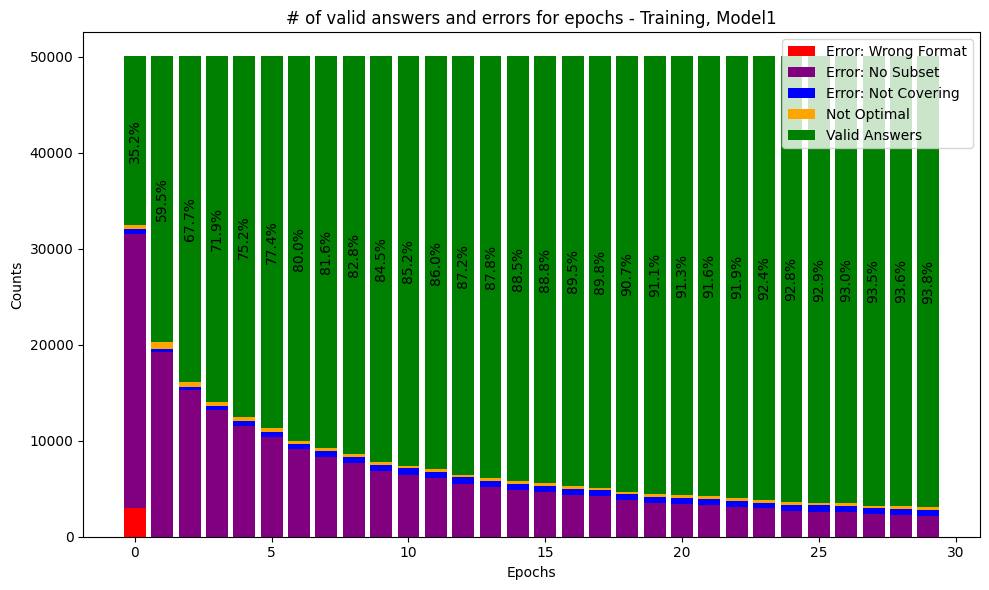

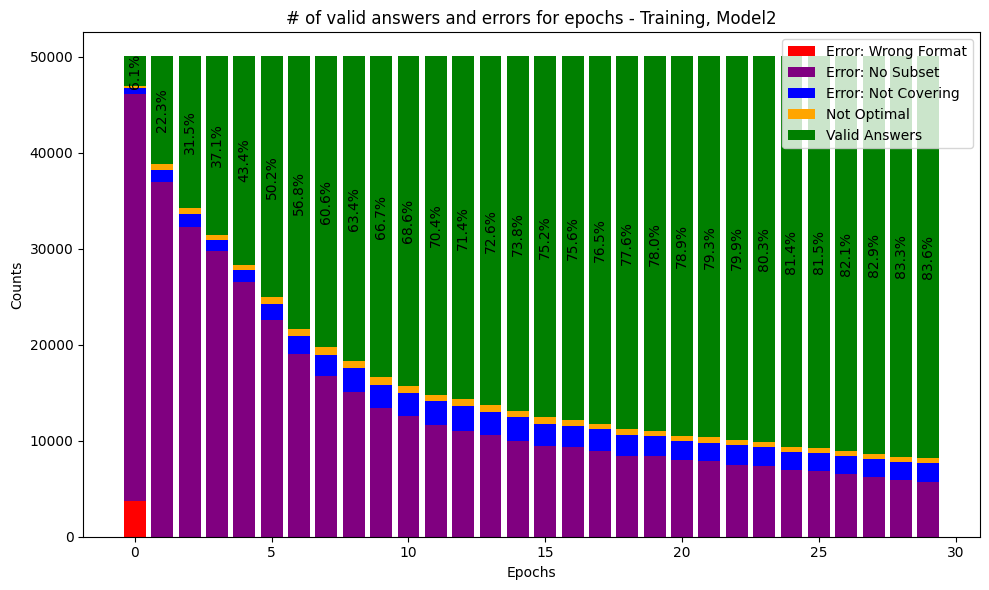

In [63]:
epochs1 = range(len(training_total_sets_model1))
epochs2 = range(len(training_total_sets_model2))

# Helper function to add labels to the bars
def add_labels(ax, valid_counts, total_counts, bottom):
    for epoch in range(len(valid_counts)):
        if total_counts[epoch] > 0:  # Avoid division by zero
            percentage = (valid_counts[epoch] / total_counts[epoch]) * 100
            ax.text(epoch, bottom[epoch] + valid_counts[epoch] / 2, f'{percentage:.1f}%', ha='center', va='center', color='black', rotation=90)

# Model 1
plt.figure(figsize=(10, 6))
total_counts_model1_training = training_error_wrong_format_model1 + training_error_no_subset_model1 + training_error_not_covering_model1 + training_valid_answers_model1 + training_not_optimal_model1
bottom_model1_training = training_error_wrong_format_model1 + training_error_no_subset_model1 + training_error_not_covering_model1 + training_not_optimal_model1

plt.bar(epochs1, training_error_wrong_format_model1, label='Error: Wrong Format', color='red')
plt.bar(epochs1, training_error_no_subset_model1, bottom=training_error_wrong_format_model1, label='Error: No Subset', color='purple')
plt.bar(epochs1, training_error_not_covering_model1, bottom=training_error_wrong_format_model1 + training_error_no_subset_model1, label='Error: Not Covering', color='blue')
plt.bar(epochs1, training_not_optimal_model1, bottom=training_error_wrong_format_model1 + training_error_no_subset_model1 + training_error_not_covering_model1, label='Not Optimal', color='orange')
bars = plt.bar(epochs1, training_valid_answers_model1, bottom=bottom_model1_training, label='Valid Answers', color='green')
add_labels(plt.gca(), training_valid_answers_model1, total_counts_model1_training, bottom_model1_training)

plt.xlabel('Epochs')
plt.ylabel('Counts')
plt.title('# of valid answers and errors for epochs - Training, Model1')
plt.legend()
plt.tight_layout()
plt.show()

# Model 2
plt.figure(figsize=(10, 6))
total_counts_model2_training = training_error_wrong_format_model2 + training_error_no_subset_model2 + training_error_not_covering_model2 + training_valid_answers_model2 + training_not_optimal_model2
bottom_model2_training = training_error_wrong_format_model2 + training_error_no_subset_model2 + training_error_not_covering_model2 + training_not_optimal_model2

plt.bar(epochs2, training_error_wrong_format_model2, label='Error: Wrong Format', color='red')
plt.bar(epochs2, training_error_no_subset_model2, bottom=training_error_wrong_format_model2, label='Error: No Subset', color='purple')
plt.bar(epochs2, training_error_not_covering_model2, bottom=training_error_wrong_format_model2 + training_error_no_subset_model2, label='Error: Not Covering', color='blue')
plt.bar(epochs2, training_not_optimal_model2, bottom=training_error_wrong_format_model2 + training_error_no_subset_model2 + training_error_not_covering_model2, label='Not Optimal', color='orange')
bars = plt.bar(epochs2, training_valid_answers_model2, bottom=bottom_model2_training, label='Valid Answers', color='green')
add_labels(plt.gca(), training_valid_answers_model2, total_counts_model2_training, bottom_model2_training)

plt.xlabel('Epochs')
plt.ylabel('Counts')
plt.title('# of valid answers and errors for epochs - Training, Model2')
plt.legend()
plt.tight_layout()
plt.show()

In [51]:
total_sets_model1= validtest1['validation_totalsets_epochs']
#Validation - Model1
validation_valid_answers_model1= validtest1['validation_valid_answers_epochs']
validation_error_wrong_format_model1= validtest1['validation_error_wrong_format_count_epochs']
validation_error_no_subset_model1= validtest1['validation_error_no_subset_count_epochs']
validation_error_not_covering_model1= validtest1['validation_error_not_covering_count_epochs']

#test - Model1
test_valid_answers_model1= validtest1['test_valid_answers_epochs']
test_error_wrong_format_model1= validtest1['test_error_wrong_format_count_epochs']
test_error_no_subset_model1= validtest1['test_error_no_subset_count_epochs']
test_error_covering_model1= validtest1['test_error_not_covering_count_epochs']

###############################################################################################
total_sets_model2= validtest2['validation_totalsets_epochs']
#Validation - Model2
validation_valid_answers_model2= validtest2['validation_valid_answers_epochs']
validation_error_wrong_format_model2= validtest2['validation_error_wrong_format_count_epochs']
validation_error_no_subset_model2= validtest2['validation_error_no_subset_count_epochs']
validation_error_not_covering_model2= validtest2['validation_error_not_covering_count_epochs']

#test - Model2
test_valid_answers_model2= validtest2['test_valid_answers_epochs']
test_error_wrong_format_model2= validtest2['test_error_wrong_format_count_epochs']
test_error_no_subset_model2= validtest2['test_error_no_subset_count_epochs']
test_error_covering_model2= validtest2['test_error_not_covering_count_epochs']


In [59]:
# Calculate "not-optimal-error"
# Convert lists to numpy arrays
total_sets_model1 = np.array(validtest1['validation_totalsets_epochs'])
validation_valid_answers_model1 = np.array(validtest1['validation_valid_answers_epochs'])
validation_error_wrong_format_model1 = np.array(validtest1['validation_error_wrong_format_count_epochs'])
validation_error_no_subset_model1 = np.array(validtest1['validation_error_no_subset_count_epochs'])
validation_error_not_covering_model1 = np.array(validtest1['validation_error_not_covering_count_epochs'])

test_valid_answers_model1 = np.array(validtest1['test_valid_answers_epochs'])
test_error_wrong_format_model1 = np.array(validtest1['test_error_wrong_format_count_epochs'])
test_error_no_subset_model1 = np.array(validtest1['test_error_no_subset_count_epochs'])
test_error_covering_model1 = np.array(validtest1['test_error_not_covering_count_epochs'])

total_sets_model2 = np.array(validtest2['validation_totalsets_epochs'])
validation_valid_answers_model2 = np.array(validtest2['validation_valid_answers_epochs'])
validation_error_wrong_format_model2 = np.array(validtest2['validation_error_wrong_format_count_epochs'])
validation_error_no_subset_model2 = np.array(validtest2['validation_error_no_subset_count_epochs'])
validation_error_not_covering_model2 = np.array(validtest2['validation_error_not_covering_count_epochs'])

test_valid_answers_model2 = np.array(validtest2['test_valid_answers_epochs'])
test_error_wrong_format_model2 = np.array(validtest2['test_error_wrong_format_count_epochs'])
test_error_no_subset_model2 = np.array(validtest2['test_error_no_subset_count_epochs'])
test_error_covering_model2 = np.array(validtest2['test_error_not_covering_count_epochs'])

# Calculate "not-optimal-error"
validation_not_optimal_error_model1 = total_sets_model1 - (validation_valid_answers_model1 + validation_error_wrong_format_model1 + validation_error_no_subset_model1 + validation_error_not_covering_model1)
test_not_optimal_error_model1 = total_sets_model1 - (test_valid_answers_model1 + test_error_wrong_format_model1 + test_error_no_subset_model1 + test_error_covering_model1)

validation_not_optimal_error_model2 = total_sets_model2 - (validation_valid_answers_model2 + validation_error_wrong_format_model2 + validation_error_no_subset_model2 + validation_error_not_covering_model2)
test_not_optimal_error_model2 = total_sets_model2 - (test_valid_answers_model2 + test_error_wrong_format_model2 + test_error_no_subset_model2 + test_error_covering_model2)

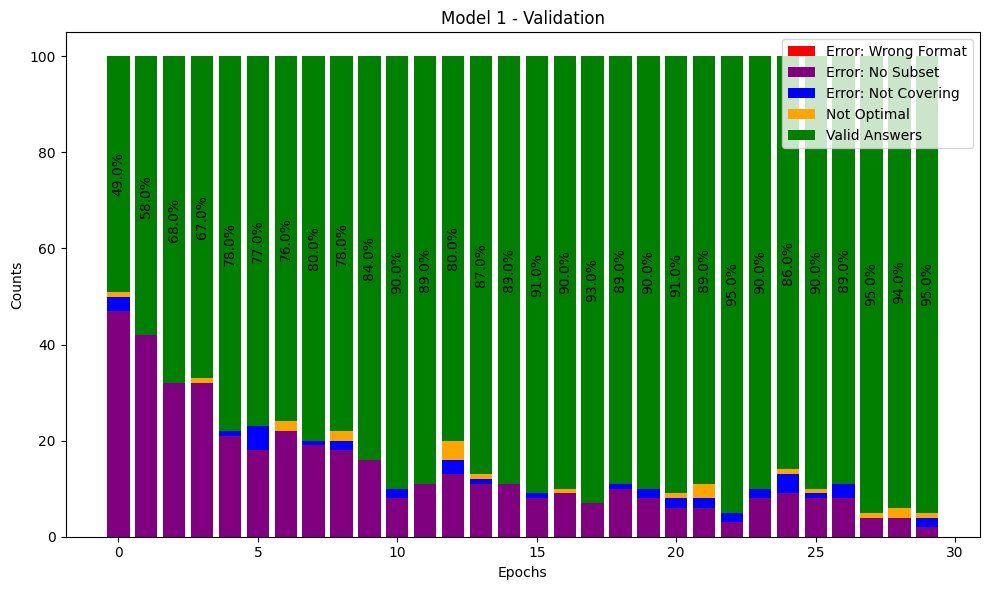

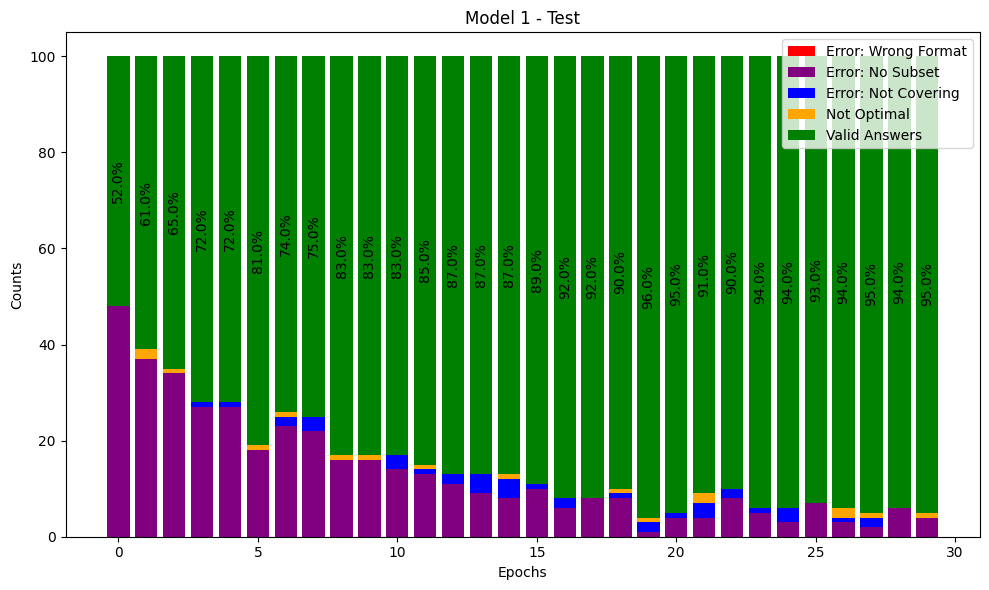

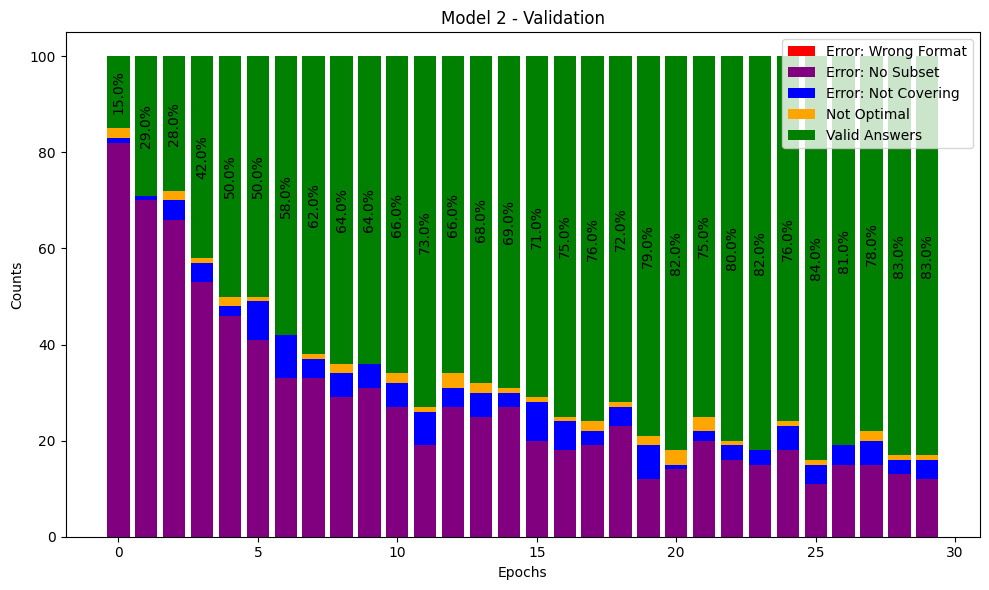

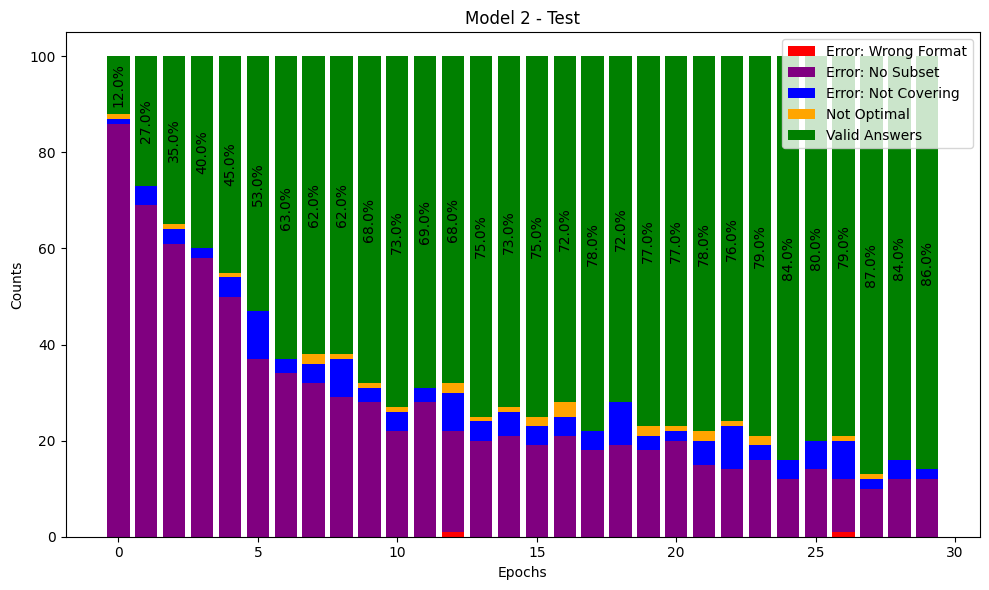

In [60]:
# Helper function to add labels to the bars
def add_labels(ax, valid_counts, total_counts, bottom):
    for epoch in epochs:
        if total_counts[epoch] > 0:  # Avoid division by zero
            percentage = (valid_counts[epoch] / total_counts[epoch]) * 100
            ax.text(epoch, bottom[epoch] + valid_counts[epoch] / 2, f'{percentage:.1f}%', ha='center', va='center', color='black', rotation=90)

epochs = range(len(total_sets_model1))

# Plot for Model 1 - Validation
plt.figure(figsize=(10, 6))
total_counts_model1_validation = validation_error_wrong_format_model1 + validation_error_no_subset_model1 + validation_error_not_covering_model1 + validation_valid_answers_model1 + validation_not_optimal_error_model1
bottom_model1_validation = validation_error_wrong_format_model1 + validation_error_no_subset_model1 + validation_error_not_covering_model1 + validation_not_optimal_error_model1

plt.bar(epochs, validation_error_wrong_format_model1, label='Error: Wrong Format', color='red')
plt.bar(epochs, validation_error_no_subset_model1, bottom=validation_error_wrong_format_model1, label='Error: No Subset', color='purple')
plt.bar(epochs, validation_error_not_covering_model1, bottom=validation_error_wrong_format_model1 + validation_error_no_subset_model1, label='Error: Not Covering', color='blue')
plt.bar(epochs, validation_not_optimal_error_model1, bottom=validation_error_wrong_format_model1 + validation_error_no_subset_model1 + validation_error_not_covering_model1, label='Not Optimal', color='orange')
bars = plt.bar(epochs, validation_valid_answers_model1, bottom=bottom_model1_validation, label='Valid Answers', color='green')
add_labels(plt.gca(), validation_valid_answers_model1, total_counts_model1_validation, bottom_model1_validation)

plt.title('Model 1 - Validation')
plt.xlabel('Epochs')
plt.ylabel('Counts')
plt.legend()
plt.tight_layout()
plt.show()

# Plot for Model 1 - Test
plt.figure(figsize=(10, 6))
total_counts_model1_test = test_error_wrong_format_model1 + test_error_no_subset_model1 + test_error_covering_model1 + test_valid_answers_model1 + test_not_optimal_error_model1
bottom_model1_test = test_error_wrong_format_model1 + test_error_no_subset_model1 + test_error_covering_model1 + test_not_optimal_error_model1

plt.bar(epochs, test_error_wrong_format_model1, label='Error: Wrong Format', color='red')
plt.bar(epochs, test_error_no_subset_model1, bottom=test_error_wrong_format_model1, label='Error: No Subset', color='purple')
plt.bar(epochs, test_error_covering_model1, bottom=test_error_wrong_format_model1 + test_error_no_subset_model1, label='Error: Not Covering', color='blue')
plt.bar(epochs, test_not_optimal_error_model1, bottom=test_error_wrong_format_model1 + test_error_no_subset_model1 + test_error_covering_model1, label='Not Optimal', color='orange')
bars = plt.bar(epochs, test_valid_answers_model1, bottom=bottom_model1_test, label='Valid Answers', color='green')
add_labels(plt.gca(), test_valid_answers_model1, total_counts_model1_test, bottom_model1_test)

plt.title('Model 1 - Test')
plt.xlabel('Epochs')
plt.ylabel('Counts')
plt.legend()
plt.tight_layout()
plt.show()

# Plot for Model 2 - Validation
plt.figure(figsize=(10, 6))
total_counts_model2_validation = validation_error_wrong_format_model2 + validation_error_no_subset_model2 + validation_error_not_covering_model2 + validation_valid_answers_model2 + validation_not_optimal_error_model2
bottom_model2_validation = validation_error_wrong_format_model2 + validation_error_no_subset_model2 + validation_error_not_covering_model2 + validation_not_optimal_error_model2

plt.bar(epochs, validation_error_wrong_format_model2, label='Error: Wrong Format', color='red')
plt.bar(epochs, validation_error_no_subset_model2, bottom=validation_error_wrong_format_model2, label='Error: No Subset', color='purple')
plt.bar(epochs, validation_error_not_covering_model2, bottom=validation_error_wrong_format_model2 + validation_error_no_subset_model2, label='Error: Not Covering', color='blue')
plt.bar(epochs, validation_not_optimal_error_model2, bottom=validation_error_wrong_format_model2 + validation_error_no_subset_model2 + validation_error_not_covering_model2, label='Not Optimal', color='orange')
bars = plt.bar(epochs, validation_valid_answers_model2, bottom=bottom_model2_validation, label='Valid Answers', color='green')
add_labels(plt.gca(), validation_valid_answers_model2, total_counts_model2_validation, bottom_model2_validation)

plt.title('Model 2 - Validation')
plt.xlabel('Epochs')
plt.ylabel('Counts')
plt.legend()
plt.tight_layout()
plt.show()

# Plot for Model 2 - Test
plt.figure(figsize=(10, 6))
total_counts_model2_test = test_error_wrong_format_model2 + test_error_no_subset_model2 + test_error_covering_model2 + test_valid_answers_model2 + test_not_optimal_error_model2
bottom_model2_test = test_error_wrong_format_model2 + test_error_no_subset_model2 + test_error_covering_model2 + test_not_optimal_error_model2

plt.bar(epochs, test_error_wrong_format_model2, label='Error: Wrong Format', color='red')
plt.bar(epochs, test_error_no_subset_model2, bottom=test_error_wrong_format_model2, label='Error: No Subset', color='purple')
plt.bar(epochs, test_error_covering_model2, bottom=test_error_wrong_format_model2 + test_error_no_subset_model2, label='Error: Not Covering', color='blue')
plt.bar(epochs, test_not_optimal_error_model2, bottom=test_error_wrong_format_model2 + test_error_no_subset_model2 + test_error_covering_model2, label='Not Optimal', color='orange')
bars = plt.bar(epochs, test_valid_answers_model2, bottom=bottom_model2_test, label='Valid Answers', color='green')
add_labels(plt.gca(), test_valid_answers_model2, total_counts_model2_test, bottom_model2_test)

plt.title('Model 2 - Test')
plt.xlabel('Epochs')
plt.ylabel('Counts')
plt.legend()
plt.tight_layout()
plt.show()